# Win chance at 10 vs 15 minutes: EDA

**Goal:** use live game data (from `lol_snapshots.py`) to estimate blue's chance of winning at the 10- or
15-minute mark. This notebook explores `lol_10min_all.csv` and `lol_15min_all.csv` and works out which
mark is the better place to make that prediction.

**The catch:** the live game API doesn't provide everything the dataset has. Gold, XP, tower plates and wards
are missing live, and CS only updates in steps of 10. Every comparison below is done twice: once with
**live features** (what a real live prediction can use) and once with **all features** (to show what's lost).

**How the comparison stays fair:** both files contain the same matches. The 15-minute file is the same games
minus 59 that ended before 15:00. Every 10 vs 15 comparison uses only the matches in both files, with the
same cross-validation folds, so any difference comes from the minute, not from different games.

Modeling uses plain NumPy (logistic regression written by hand), so the notebook runs without scikit-learn
or SciPy. The final model is a short list of numbers that `lol_snapshots.py` can use with no extra libraries.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

# Chart style: blue = 10 min, orange = 15 min, everywhere.
C10, C15 = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
MINUTE_COLOR = {10: C10, 15: C15}
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})
RNG_SEED = 42

## 1. Load the data

In [2]:
DATA_DIR = Path(".")   # the CSVs sit next to this notebook
raw10 = pd.read_csv(DATA_DIR / "lol_10min_all.csv")
raw15 = pd.read_csv(DATA_DIR / "lol_15min_all.csv")

shared = sorted(set(raw10.match_id) & set(raw15.match_id))
d10 = raw10.set_index("match_id").loc[shared].reset_index()
d15 = raw15.set_index("match_id").loc[shared].reset_index()
assert (d10.blue_win.values == d15.blue_win.values).all(), "winner should match across files"

print(f"10-min file: {raw10.shape[0]:,} matches, {raw10.shape[1]} columns")
print(f"15-min file: {raw15.shape[0]:,} matches, {raw15.shape[1]} columns")
print(f"Matches in both (used for every comparison): {len(shared):,}")
print(f"In the 10-min file only (ended before 15:00): {len(raw10) - len(shared)}")

10-min file: 8,226 matches, 40 columns
15-min file: 8,167 matches, 70 columns
Matches in both (used for every comparison): 8,167
In the 10-min file only (ended before 15:00): 59


## 2. Data quality checks
Missing values, duplicates, class balance, and how the matches spread across ranks and patches.

In [3]:
for name, df in [("10 min", raw10), ("15 min", raw15)]:
    print(f"{name}: missing values = {int(df.isna().sum().sum())}, duplicate match ids = {df.match_id.duplicated().sum()}, "
          f"blue win rate = {df.blue_win.mean():.3f}")

rank_order = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD", "DIAMOND", "MASTER_PLUS"]
summary = pd.DataFrame({
    "matches": d10.rank_tier.value_counts().reindex(rank_order),
    "blue_win_rate": d10.groupby("rank_tier").blue_win.mean().reindex(rank_order).round(3),
})
display(summary)
display(raw15.patch.value_counts().rename("matches").to_frame())

10 min: missing values = 0, duplicate match ids = 0, blue win rate = 0.491
15 min: missing values = 0, duplicate match ids = 0, blue win rate = 0.492


,matches,blue_win_rate
rank_tier,,
IRON,1021,0.448
BRONZE,1013,0.485
SILVER,1025,0.530
GOLD,1021,0.483
PLATINUM,1025,0.499
EMERALD,1023,0.533
DIAMOND,1017,0.481
MASTER_PLUS,1022,0.477


,matches
patch,
16.19,3914
16.20,2662
16.18,1591


Blue wins about 49% of games, so the classes are balanced and accuracy is a reasonable metric next to
AUC. Ranks are evenly sampled (about 1,000 matches each).

### How long do games last?
This matters for the 15-minute mark. Surrender opens at 15:00, and the spike just after it is early
surrenders (about 4% of games). Those games are usually lopsided by 15:00, so they are easy to predict then.
That is part of why 15 minutes predicts better, and it's real: those games really are decided by then.

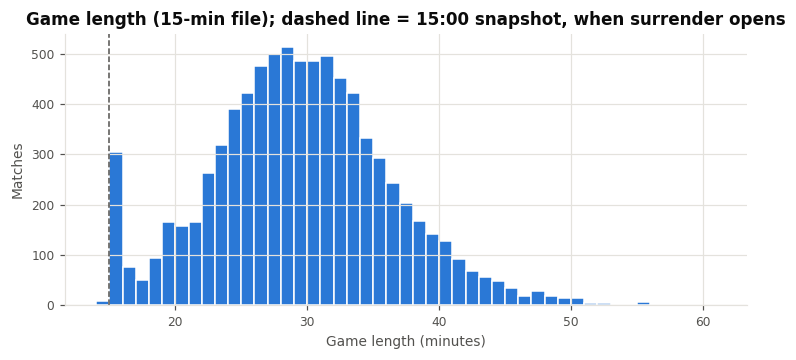

Games over by 16:00: 3.8%
Games over by 20:00: 8.5%


In [4]:
mins = raw15.game_duration_s / 60
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(mins, bins=np.arange(14, 62, 1), color=C10, edgecolor="white", linewidth=1)
ax.axvline(15, color=INK2, linewidth=1, linestyle="--")
ax.set(title="Game length (15-min file); dashed line = 15:00 snapshot, when surrender opens", xlabel="Game length (minutes)", ylabel="Matches")
plt.show()

for cutoff in (16, 20):
    print(f"Games over by {cutoff}:00: {(mins < cutoff).mean():.1%}")

## 3. Which features are available live?
`lol_snapshots.py` writes the same columns as the dataset, but only some of them can be filled from the
live API. Every feature is used as a **blue-minus-red difference**, plus first blood.

In [5]:
LIVE = ["level_sum_diff", "cs_diff", "kills_diff", "assists_diff", "towers_diff",
        "dragons_diff", "heralds_diff", "voidgrubs_diff", "blue_first_blood"]
NOT_LIVE = ["gold_diff", "xp_diff", "plates_diff", "wards_diff"]
FULL = LIVE + NOT_LIVE

availability = pd.DataFrame(
    [(f, "yes", "") for f in LIVE] + [(f, "no", "not in the live API") for f in NOT_LIVE],
    columns=["feature", "live?", "note"])
availability.loc[availability.feature == "cs_diff", "note"] = "live CS only updates in steps of 10 (see section 9)"
display(availability)

,feature,live?,note
0,level_sum_diff,yes,
1,cs_diff,yes,live CS only updates in steps of 10 (see secti...
2,kills_diff,yes,
3,assists_diff,yes,
4,towers_diff,yes,
5,dragons_diff,yes,
6,heralds_diff,yes,
7,voidgrubs_diff,yes,
8,blue_first_blood,yes,
9,gold_diff,no,not in the live API


## 4. How the features change from 10 to 15 minutes
The spread of each difference grows between 10 and 15 minutes as leads build. Two things to note:

* **Heralds are never taken by 15:00 in this data** (it spawns later), so `heralds_diff` is always 0 and
  adds nothing at either mark. It stays in the feature list because the live script records it.
* **`wards_diff` seems to be counted differently in the two files.** Its spread is about 67 at 10 minutes but
  about 6 at 15 minutes, so it is probably defined differently in the 15-minute file. Wards aren't available
  live, so this doesn't affect the live model, but don't compare that column across the files.

In [6]:
def describe(df, cols):
    return df[cols].agg(["mean", "std", "min", "max"]).T.round(2)

side_by_side = pd.concat({"10 min": describe(d10, FULL), "15 min": describe(d15, FULL)}, axis=1)
display(side_by_side)
print("Share of games where any herald was taken:",
      f"10 min = {(d10.blue_heralds + d10.red_heralds > 0).mean():.1%},",
      f"15 min = {(d15.blue_heralds + d15.red_heralds > 0).mean():.1%}")

10 min                           15 min                           
                   mean      std      min     max   mean      std      min      max
level_sum_diff     0.02     2.06     -9.0     9.0  -0.01     3.11    -12.0     12.0
cs_diff           -0.40    36.00   -140.0   133.0  -0.52    56.92   -221.0    213.0
kills_diff         0.04     4.39    -20.0    16.0  -0.00     7.27    -31.0     31.0
assists_diff      -0.01     5.04    -23.0    22.0  -0.14     8.38    -34.0     40.0
towers_diff       -0.00     0.15     -2.0     1.0   0.01     1.35     -6.0      6.0
dragons_diff      -0.09     0.92     -1.0     1.0  -0.14     1.43     -2.0      2.0
heralds_diff       0.00     0.00      0.0     0.0   0.00     0.00      0.0      0.0
voidgrubs_diff     0.27     2.43     -3.0     3.0   0.31     2.73     -3.0      3.0
blue_first_blood   0.50     0.50      0.0     1.0   0.50     0.50      0.0      1.0
gold_diff        -13.54  2110.36 -10467.0  7194.0 -54.87  4014.34 -16450.0  14489.0
xp_diff           13.73  1668.86  -8040.0  6963.0 -28.60  3502.21 -14132.0  13745.0
plates_diff        0.01     2.91    -12.0    12.0   0.08     6.72    -29.0     32.0
wards_diff        -0.83    66.97   -438.0   455.0  -0.06     5.66    -25.0     24.0

Share of games where any herald was taken: 10 min = 0.0%, 15 min = 0.0%


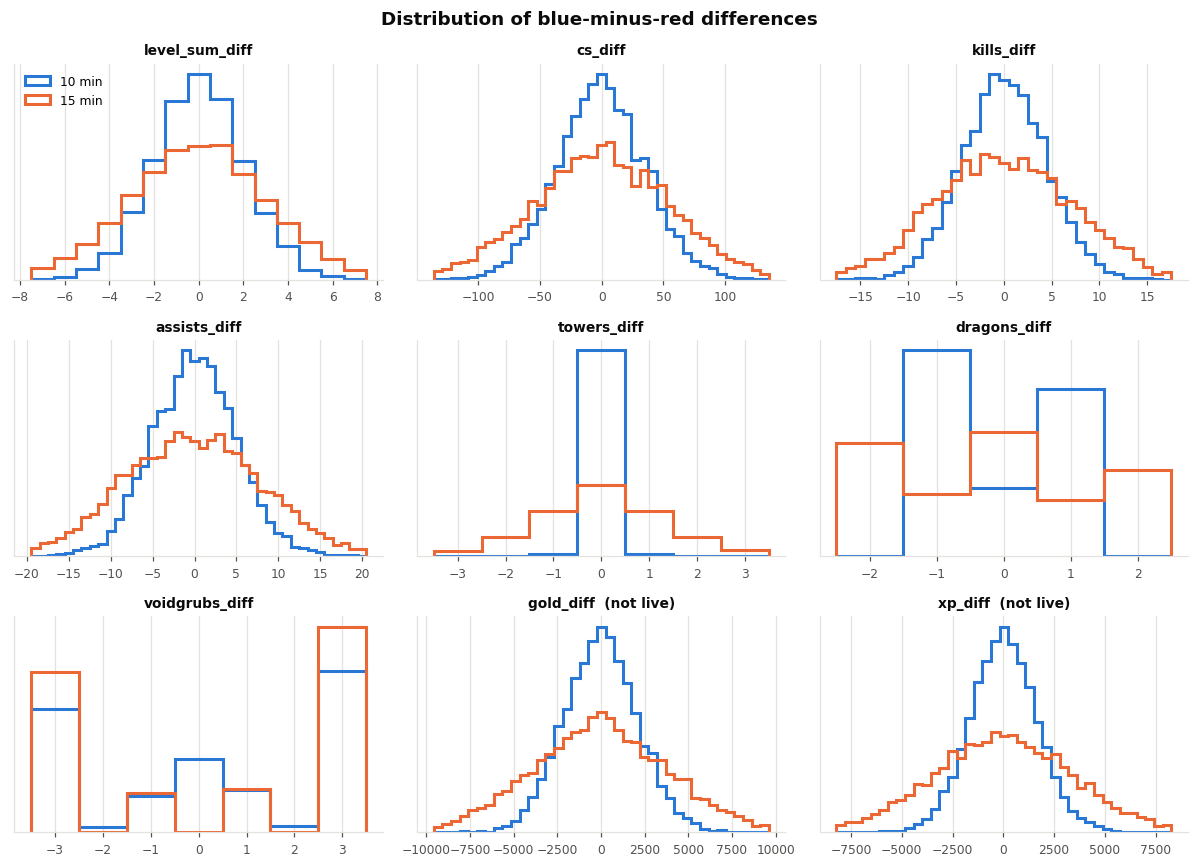

In [7]:
plot_feats = ["level_sum_diff", "cs_diff", "kills_diff", "assists_diff",
              "towers_diff", "dragons_diff", "voidgrubs_diff", "gold_diff", "xp_diff"]
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, f in zip(axes.flat, plot_feats):
    lo, hi = np.percentile(np.r_[d10[f], d15[f]], [0.5, 99.5])
    discrete = hi - lo <= 60   # small whole-number ranges get one bin per value
    bins = np.arange(np.floor(lo) - 0.5, np.ceil(hi) + 1.5) if discrete else np.linspace(lo, hi, 40)
    for minute, df in [(10, d10), (15, d15)]:
        ax.hist(df[f], bins=bins, histtype="step", linewidth=2, color=MINUTE_COLOR[minute],
                density=True, label=f"{minute} min")
    ax.set_title(f + ("" if f in LIVE else "  (not live)"), fontsize=9)
    ax.set_yticks([])
axes.flat[0].legend(loc="upper left")
fig.suptitle("Distribution of blue-minus-red differences", fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

## 5. Blue's win rate as each lead grows
Each line shows blue's actual win rate in matches grouped by the size of the lead. Only groups with at
least 50 matches are drawn. A steeper line means the feature tells you more about who wins.

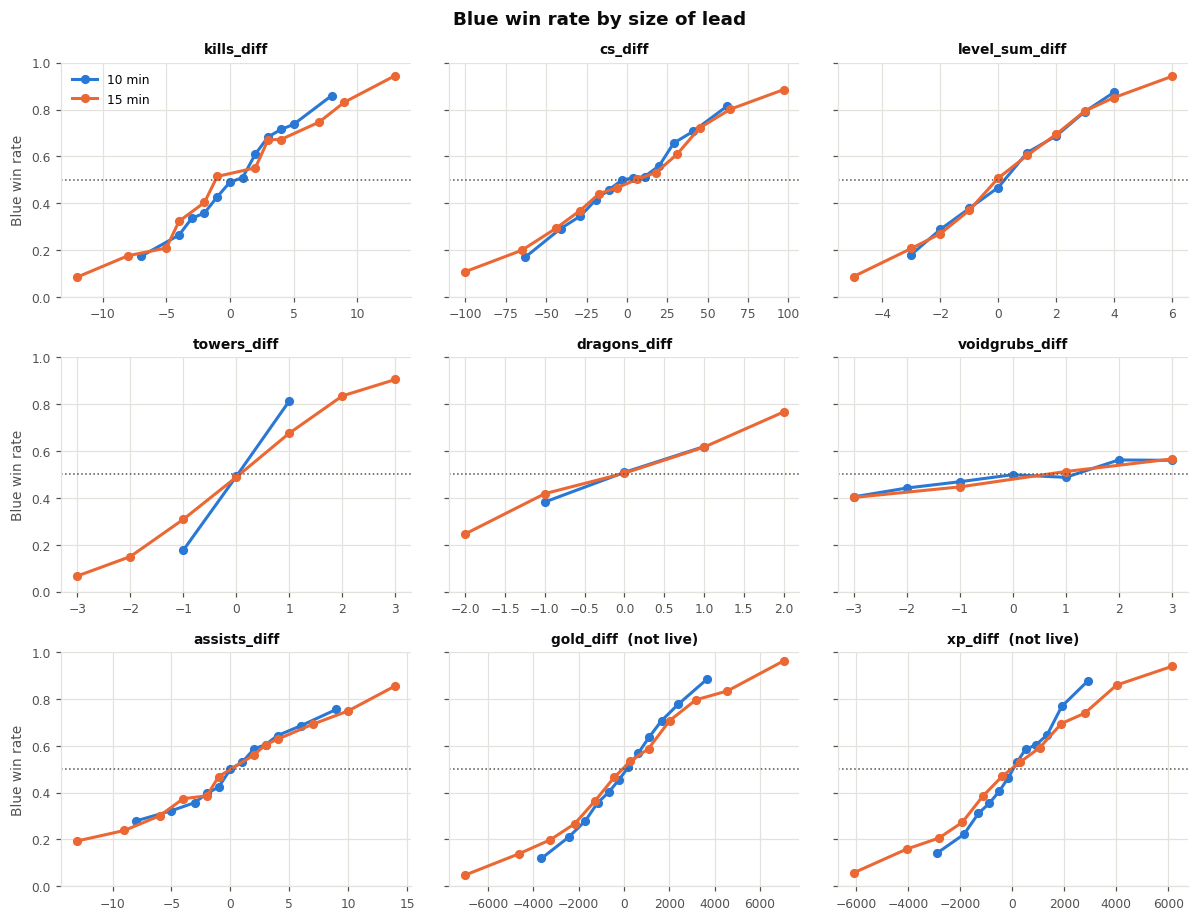

,10 min,15 min
blue win rate,,
red got first blood,0.425,0.425
blue got first blood,0.559,0.559


In [8]:
def winrate_curve(df, f, nbins=12, min_n=50):
    x = df[f]
    if x.nunique() <= 15:
        g = df.groupby(f).blue_win.agg(["mean", "size"])
    else:
        edges = np.unique(np.quantile(x, np.linspace(0, 1, nbins + 1)))
        b = pd.cut(x, edges, include_lowest=True)
        g = df.groupby(b, observed=True).agg(center=(f, "median"), mean=("blue_win", "mean"), size=("blue_win", "size"))
        g = g.set_index("center")
    return g[g["size"] >= min_n]

curve_feats = ["kills_diff", "cs_diff", "level_sum_diff", "towers_diff", "dragons_diff",
               "voidgrubs_diff", "assists_diff", "gold_diff", "xp_diff"]
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5), sharey=True)
for ax, f in zip(axes.flat, curve_feats):
    for minute, df in [(10, d10), (15, d15)]:
        g = winrate_curve(df, f)
        ax.plot(g.index, g["mean"], color=MINUTE_COLOR[minute], marker="o", markersize=5, label=f"{minute} min")
    ax.axhline(0.5, color=INK2, linewidth=1, linestyle=":")
    ax.set_title(f + ("" if f in LIVE else "  (not live)"), fontsize=9)
    ax.set_ylim(0, 1)
for ax in axes[:, 0]:
    ax.set_ylabel("Blue win rate")
axes.flat[0].legend(loc="upper left")
fig.suptitle("Blue win rate by size of lead", fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

fb = pd.DataFrame({m: df.groupby("blue_first_blood").blue_win.mean() for m, df in [("10 min", d10), ("15 min", d15)]})
fb.index = fb.index.map({0: "red got first blood", 1: "blue got first blood"})
display(fb.round(3).rename_axis("blue win rate"))

## 6. How predictive is each feature on its own?
**AUC** measures how well one number separates wins from losses: 0.5 is a coin flip, 1.0 is perfect. Here it is
calculated for each feature on its own, with the direction handled automatically (a feature that predicts
*losses* counts too).

,10,15,gain_15_vs_10,live
gold_diff,0.759,0.828,0.069,False
xp_diff,0.741,0.815,0.074,False
level_sum_diff,0.719,0.803,0.084,True
kills_diff,0.732,0.802,0.070,True
plates_diff,0.685,0.773,0.088,False
cs_diff,0.695,0.759,0.064,True
towers_diff,0.513,0.742,0.229,True
assists_diff,0.668,0.735,0.067,True
dragons_diff,0.615,0.703,0.088,True
voidgrubs_diff,0.568,0.580,0.011,True


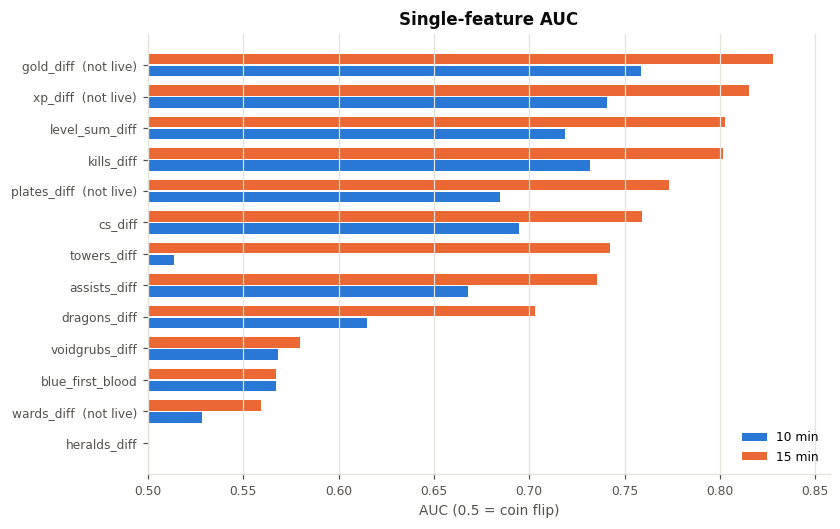

In [9]:
def auc(y, score):
    """ROC AUC through the rank-sum formula, with ties handled (no scikit-learn needed)."""
    y = np.asarray(y)
    ranks = pd.Series(np.asarray(score, dtype=float)).rank(method="average").to_numpy()
    n_pos = y.sum(); n_neg = len(y) - n_pos
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

single = pd.DataFrame({
    m: {f: max(auc(df.blue_win, df[f]), 1 - auc(df.blue_win, df[f])) for f in FULL}
    for m, df in [(10, d10), (15, d15)]
})
single["gain_15_vs_10"] = single[15] - single[10]
single["live"] = single.index.isin(LIVE)
single = single.sort_values(15)
display(single.sort_values(15, ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(single)); h = 0.38
for i, minute in enumerate((10, 15)):
    ax.barh(y + (i - 0.5) * h, single[minute] - 0.5, left=0.5, height=h - 0.04,
            color=MINUTE_COLOR[minute], label=f"{minute} min")
ax.set_yticks(y, [f + ("" if live else "  (not live)") for f, live in zip(single.index, single.live)])
ax.set_xlim(0.5, max(0.85, single[15].max() + 0.03))
ax.set(title="Single-feature AUC", xlabel="AUC (0.5 = coin flip)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

### How the live features overlap
Features that move together (kills, assists, levels) carry overlapping information, so adding all of them
helps less than their single-feature AUCs suggest.

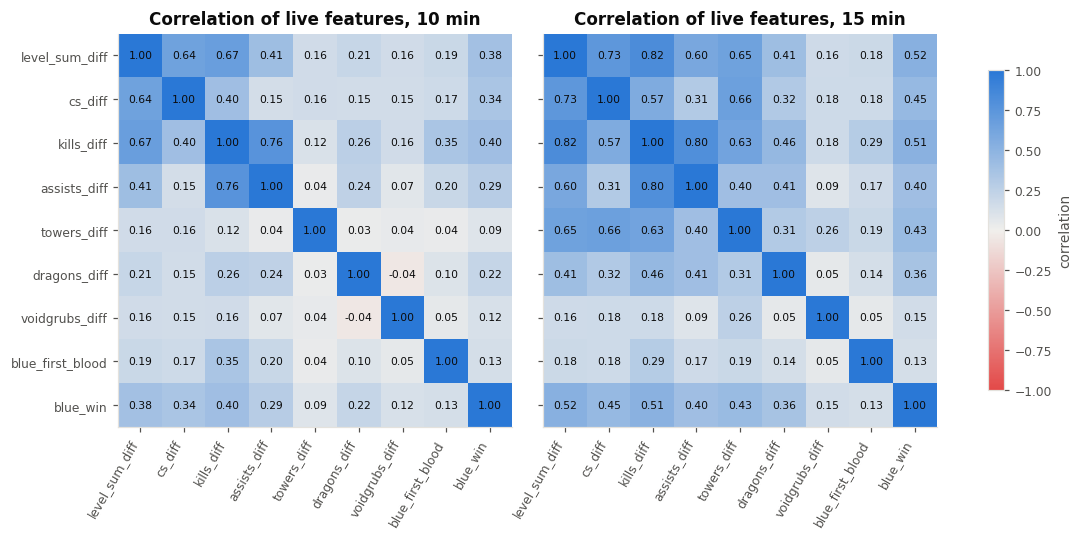

In [10]:
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#e34948", "#f0efec", "#2a78d6"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"wspace": 0.08})
for ax, (minute, df) in zip(axes, [(10, d10), (15, d15)]):
    cols = [c for c in LIVE if df[c].std() > 0] + ["blue_win"]
    corr = df[cols].corr()
    im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
    ax.set_yticks(range(len(cols)), cols if minute == 10 else [])
    ax.grid(False)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
    ax.set_title(f"Correlation of live features, {minute} min")
fig.colorbar(im, ax=axes, shrink=0.7, label="correlation")
plt.show()

## 7. Models: 10 vs 15 minutes, live features vs all features
A logistic regression for each combination, scored with 5-fold cross-validation on the **same folds**
(so 10 and 15 are compared on identical games). Metrics:

* **AUC**: how well the model ranks wins above losses (higher is better)
* **Log loss** and **Brier score**: how good the win *percentages* are (lower is better). These matter most
  here, because the goal is a win chance, not just a pick.
* **Accuracy**: share of games where the side given over 50% won

In [11]:
def fit_logreg(X, y, l2=1e-2, iters=50):
    """Logistic regression with a small L2 penalty, fit with Newton's method. X must already be scaled."""
    Xb = np.c_[np.ones(len(X)), X]
    w = np.zeros(Xb.shape[1])
    pen = np.full(Xb.shape[1], l2); pen[0] = 0          # don't shrink the intercept
    for _ in range(iters):
        p = 1 / (1 + np.exp(-Xb @ w))
        grad = Xb.T @ (p - y) + pen * w
        hess = (Xb * (p * (1 - p))[:, None]).T @ Xb + np.diag(pen)
        step = np.linalg.solve(hess, grad)
        w -= step
        if np.abs(step).max() < 1e-8:
            break
    return w

class WinModel:
    def __init__(self, features):
        self.features = features
    def fit(self, df):
        X = df[self.features].to_numpy(float)
        self.mean = X.mean(0)
        self.std = np.where(X.std(0) > 0, X.std(0), 1.0)
        self.w = fit_logreg((X - self.mean) / self.std, df.blue_win.to_numpy(float))
        return self
    def predict(self, df):
        X = (df[self.features].to_numpy(float) - self.mean) / self.std
        return 1 / (1 + np.exp(-(self.w[0] + X @ self.w[1:])))

def metrics(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"AUC": auc(y, p),
            "log_loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
            "brier": np.mean((p - y) ** 2),
            "accuracy": np.mean((p > 0.5) == y)}

# Stratified 5-fold split, shared by every model.
rng = np.random.default_rng(RNG_SEED)
y_all = d10.blue_win.to_numpy()
folds = np.empty(len(y_all), int)
for cls in (0, 1):
    idx = rng.permutation(np.flatnonzero(y_all == cls))
    folds[idx] = np.arange(len(idx)) % 5

def out_of_fold(df, features, test_transform=None):
    """Predicted win chance for every match, each from a model that never saw that match."""
    p = np.empty(len(df))
    for k in range(5):
        train, test = df[folds != k], df[folds == k]
        if test_transform is not None:
            test = test_transform(test)
        p[folds == k] = WinModel(features).fit(train).predict(test)
    return p

oof = {(m, fs): out_of_fold(df, feats)
       for m, df in [(10, d10), (15, d15)]
       for fs, feats in [("live", LIVE), ("all", FULL)]}
results = pd.DataFrame({k: metrics(y_all, p) for k, p in oof.items()}).T
results.index.names = ["minute", "features"]
baseline = metrics(y_all, np.full(len(y_all), y_all.mean()))
print(f"Baseline (always predict {y_all.mean():.3f}): log loss {baseline['log_loss']:.4f}, brier {baseline['brier']:.4f}")
display(results.round(4))

Baseline (always predict 0.492): log loss 0.6930, brier 0.2499


AUC  log_loss   brier  accuracy
minute features                                    
10     live      0.7702    0.5703  0.1948    0.6963
       all       0.7720    0.5688  0.1941    0.6978
15     live      0.8370    0.4961  0.1647    0.7530
       all       0.8390    0.4931  0.1638    0.7555

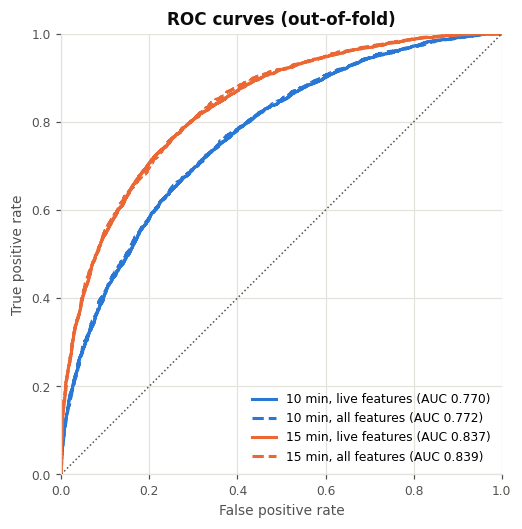

In [12]:
def roc_points(y, p):
    order = np.argsort(-p)
    y = y[order]
    tpr = np.r_[0, np.cumsum(y) / y.sum()]
    fpr = np.r_[0, np.cumsum(1 - y) / (1 - y).sum()]
    return fpr, tpr

fig, ax = plt.subplots(figsize=(5.6, 5.2))
for (minute, fs), p in oof.items():
    fpr, tpr = roc_points(y_all, p)
    ax.plot(fpr, tpr, color=MINUTE_COLOR[minute], linestyle="-" if fs == "live" else "--",
            label=f"{minute} min, {fs} features (AUC {results.loc[(minute, fs), 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax.set(title="ROC curves (out-of-fold)", xlabel="False positive rate", ylabel="True positive rate",
       xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal")
ax.legend(loc="lower right")
plt.show()

### Is the 15-minute gain real?
A paired bootstrap: resample the same matches 1,000 times and recompute the AUC gap between the 15- and
10-minute live models each time. If the 95% interval is entirely above zero, 15 minutes is reliably better,
not better by chance.

AUC gain from waiting until 15 min (live features): +0.0667  95% CI [+0.0599, +0.0732]


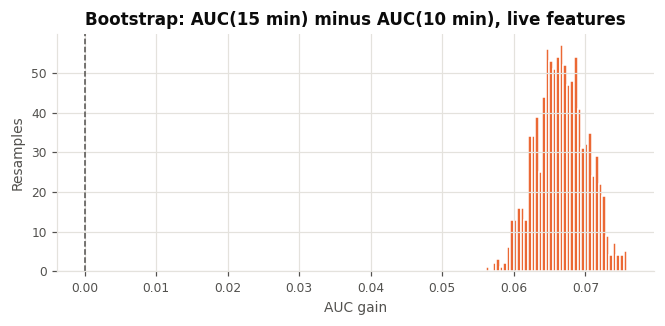

In [13]:
boot_rng = np.random.default_rng(RNG_SEED)
p10, p15 = oof[(10, "live")], oof[(15, "live")]
gaps = []
for _ in range(1000):
    i = boot_rng.integers(0, len(y_all), len(y_all))
    gaps.append(auc(y_all[i], p15[i]) - auc(y_all[i], p10[i]))
gaps = np.array(gaps)
lo, hi = np.percentile(gaps, [2.5, 97.5])
print(f"AUC gain from waiting until 15 min (live features): {np.mean(gaps):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(gaps, bins=40, color=C15, edgecolor="white", linewidth=1)
ax.axvline(0, color=INK2, linewidth=1, linestyle="--")
ax.set(title="Bootstrap: AUC(15 min) minus AUC(10 min), live features", xlabel="AUC gain", ylabel="Resamples")
plt.show()

## 8. Does it hold up at every rank?
The same out-of-fold predictions, scored separately for each rank tier.

,10,15,gain
IRON,0.778,0.856,0.078
BRONZE,0.785,0.839,0.054
SILVER,0.778,0.845,0.067
GOLD,0.762,0.827,0.065
PLATINUM,0.764,0.819,0.055
EMERALD,0.751,0.823,0.072
DIAMOND,0.768,0.828,0.061
MASTER_PLUS,0.779,0.857,0.078


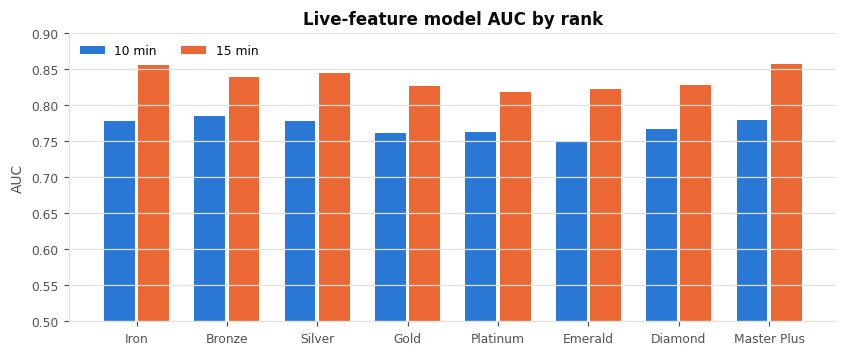

In [14]:
by_rank = pd.DataFrame({
    m: {r: auc(y_all[d10.rank_tier == r], oof[(m, "live")][d10.rank_tier == r]) for r in rank_order}
    for m in (10, 15)})
by_rank["gain"] = by_rank[15] - by_rank[10]
display(by_rank.round(3))

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(rank_order)); w = 0.38
for i, minute in enumerate((10, 15)):
    ax.bar(x + (i - 0.5) * w, by_rank[minute] - 0.5, bottom=0.5, width=w - 0.04,
           color=MINUTE_COLOR[minute], label=f"{minute} min")
ax.set_xticks(x, [r.replace("_", " ").title() for r in rank_order])
ax.set_ylim(0.5, max(0.9, by_rank[15].max() + 0.03))
ax.set(title="Live-feature model AUC by rank", ylabel="AUC")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
plt.show()

## 9. Does live CS rounding hurt?
The live API only updates CS in steps of 10, so each player's live CS is up to 9 below the real number. To
mimic that, the models are trained on exact CS and tested on CS with 0–9 removed per player (5 players a
side). This is an approximation, since the dataset only has team totals.

In [15]:
def round_cs_like_live(df, seed=RNG_SEED):
    r = np.random.default_rng(seed)
    df = df.copy()
    lost_blue = r.integers(0, 10, (len(df), 5)).sum(1)
    lost_red = r.integers(0, 10, (len(df), 5)).sum(1)
    df["cs_diff"] = df["cs_diff"] - lost_blue + lost_red
    return df

rows = {}
for minute, df in [(10, d10), (15, d15)]:
    rows[(minute, "exact CS")] = metrics(y_all, oof[(minute, "live")])
    rows[(minute, "live-rounded CS")] = metrics(y_all, out_of_fold(df, LIVE, round_cs_like_live))
display(pd.DataFrame(rows).T.round(4))

AUC  log_loss   brier  accuracy
10 exact CS         0.7702    0.5703  0.1948    0.6963
   live-rounded CS  0.7683    0.5721  0.1956    0.6971
15 exact CS         0.8370    0.4961  0.1647    0.7530
   live-rounded CS  0.8364    0.4968  0.1650    0.7539

## 10. Are the win percentages trustworthy?
Since the output is a win chance, it should be **calibrated**: among games where the model says 70%, blue
should win about 70%. Matches are grouped into 10 equal-sized groups by predicted chance.

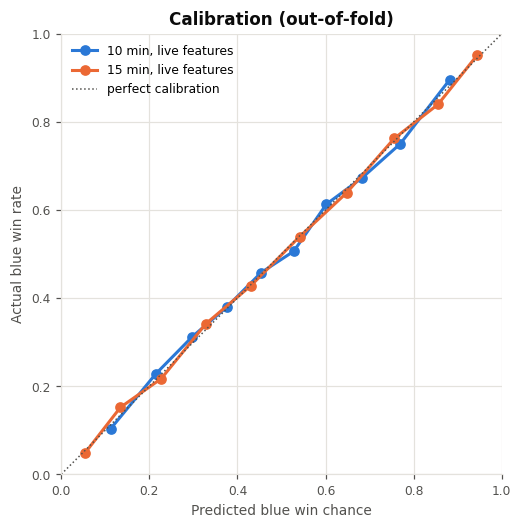

In [16]:
fig, ax = plt.subplots(figsize=(5.4, 5.2))
for minute in (10, 15):
    p = oof[(minute, "live")]
    g = pd.DataFrame({"p": p, "y": y_all}).groupby(pd.qcut(p, 10), observed=True).mean()
    ax.plot(g.p, g.y, color=MINUTE_COLOR[minute], marker="o", markersize=6, label=f"{minute} min, live features")
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":", label="perfect calibration")
ax.set(title="Calibration (out-of-fold)", xlabel="Predicted blue win chance", ylabel="Actual blue win rate",
       xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## 11. Is the 10-minute prediction good enough to show too?
15 minutes is clearly better, but that doesn't make 10 minutes useless. Both models are well calibrated
(section 10), so the 10-minute percentages are honest, just more cautious. This compares how often each
model makes a confident call and how often those calls are right, plus how much the prediction moves between
the two marks in the same game.

In [17]:
p10, p15 = oof[(10, "live")], oof[(15, "live")]
conf_rows = {}
for minute, p in [(10, p10), (15, p15)]:
    conf = np.maximum(p, 1 - p)          # confidence in whichever side is favoured
    r = {"picks the winner": np.mean((p > 0.5) == y_all),
         "too close to call (40-60%)": np.mean(conf < 0.6)}
    for t in (0.7, 0.8, 0.9):
        mask = conf >= t
        r[f"games called at >= {t:.0%}"] = mask.mean()
        r[f"  ...right when called at >= {t:.0%}"] = np.mean((p[mask] > 0.5) == y_all[mask])
    conf_rows[f"{minute} min"] = r
display(pd.DataFrame(conf_rows).round(3))

flipped = (p10 > 0.5) != (p15 > 0.5)
print(f"Favourite changes between 10 and 15 min: {flipped.mean():.1%} of games")
print(f"  when it changes, the 15-min pick is right {np.mean((p15[flipped] > 0.5) == y_all[flipped]):.1%} of the time")
print(f"Average move in blue's win chance from 10 to 15 min: {np.mean(np.abs(p15 - p10)) * 100:.1f} points")

,10 min,15 min
picks the winner,0.696,0.753
too close to call (40-60%),0.268,0.185
games called at >= 70%,0.482,0.623
...right when called at >= 70%,0.808,0.851
games called at >= 80%,0.254,0.430
...right when called at >= 80%,0.873,0.892
games called at >= 90%,0.070,0.205
...right when called at >= 90%,0.937,0.948


Favourite changes between 10 and 15 min: 18.1% of games
  when it changes, the 15-min pick is right 65.7% of the time
Average move in blue's win chance from 10 to 15 min: 12.6 points


**Verdict:** the 10-minute model is a fair early read (about 70% of winners picked, honest percentages), and
the 15-minute model is the firmer call. The favourite changes in roughly 1 game in 5 between the marks, so
showing both is informative, not just repetition. Both models are exported.

## 12. Final models
Each model is refit on every match at its minute and saved to `win_model.json`, which holds the feature
list, scaling and coefficients for each minute. `lol_snapshots.py` prints a win chance at each snapshot that
has a model.

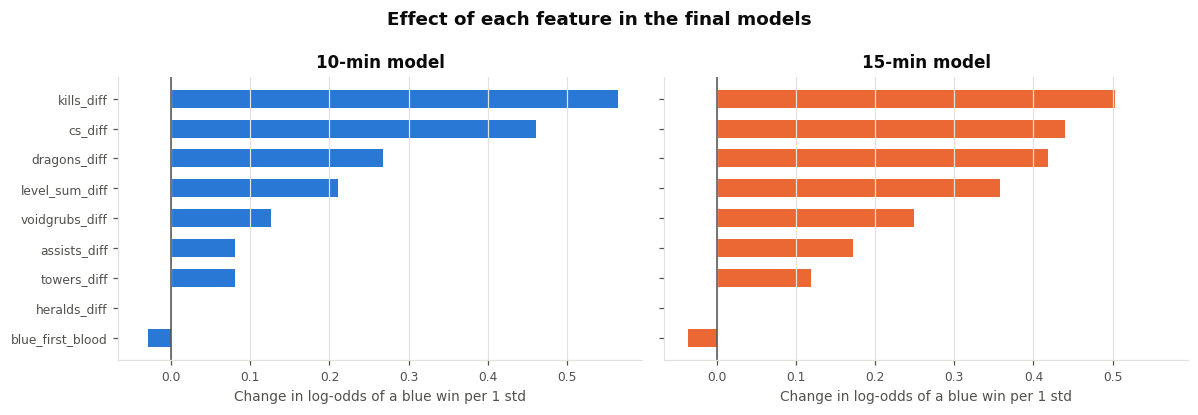

Saved C:\Users\austi\OneDrive\Desktop\LOL Project\win_model.json


In [18]:
final_models = {10: WinModel(LIVE).fit(d10), 15: WinModel(LIVE).fit(d15)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (minute, mdl) in zip(axes, final_models.items()):
    coef = pd.Series(mdl.w[1:], index=LIVE).sort_values()
    ax.barh(coef.index, coef.values, color=MINUTE_COLOR[minute], height=0.6)
    ax.axvline(0, color=INK2, linewidth=1)
    ax.set(title=f"{minute}-min model", xlabel="Change in log-odds of a blue win per 1 std")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("Effect of each feature in the final models", fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

model_file = Path("win_model.json")
model_file.write_text(json.dumps({"models": [
    {
        "minute": minute,
        "features": LIVE,
        "mean": mdl.mean.tolist(),
        "std": mdl.std.tolist(),
        "intercept": mdl.w[0],
        "coef": mdl.w[1:].tolist(),
        "cv_metrics": {k: round(v, 4) for k, v in results.loc[(minute, "live")].items()},
        "trained_on": f"{len(d10)} matches from lol_{minute}min_all.csv (matches present in both files)",
    }
    for minute, mdl in final_models.items()
]}, indent=1))
print(f"Saved {model_file.resolve()}")

### Try it on the rows `lol_snapshots.py` already saved
These are the test games recorded so far (rank `TEST`). Rows saved before the execution fix may be off by a
kill or so.

In [19]:
saved_models = {m["minute"]: m for m in json.loads(model_file.read_text())["models"]}

def win_chance(row):
    model = saved_models[row["minute"]]
    x = (np.array([row[f] for f in model["features"]], float) - model["mean"]) / model["std"]
    return 1 / (1 + np.exp(-(model["intercept"] + x @ np.array(model["coef"]))))

snaps = pd.read_csv("lol_snapshots.csv")
snaps = snaps[snaps.minute.isin(saved_models)].copy()
snaps["blue_first_blood"] = snaps["blue_first_blood"].fillna(0.5)   # no first blood yet -> neutral
snaps["blue_win_chance"] = snaps.apply(win_chance, axis=1).round(3)
display(snaps[["match_id", "minute", "kills_diff", "cs_diff", "level_sum_diff", "dragons_diff",
               "blue_win_chance", "blue_win"]])

,match_id,minute,kills_diff,cs_diff,level_sum_diff,dragons_diff,blue_win_chance,blue_win
0,LIVE_20261021_161705,10,-3,-10,0,0,0.362,1
1,LIVE_20261021_161705,15,0,-30,-1,-1,0.370,1
2,LIVE_20261021_201603,10,-7,-10,-4,-1,0.164,0
3,LIVE_20261021_201603,15,-16,-50,-8,-2,0.033,0
4,LIVE_20261021_211809,10,-1,-20,-5,0,0.284,0
5,LIVE_20261021_211809,15,-1,-50,-6,1,0.237,0


## Summary

* **15 minutes is the better mark.** With the features available live, cross-validated AUC goes from about
  0.77 at 10 minutes to about 0.84 at 15. The bootstrap interval for the gain is well above zero, and
  15 minutes wins at every rank. Log loss and Brier score improve too, so the win percentages are sharper,
  not just the ranking.
* **10 minutes is still a useful early read.** It picks about 70% of winners and its percentages are honest,
  just more cautious. The favourite changes in about 1 game in 5 by 15:00, so both predictions are shown live.
* **Losing gold, XP, plates and wards barely matters.** Using all features adds only about 0.002 AUC at either
  mark. Levels, CS and kills carry nearly the same information as gold and XP.
* **Towers make the biggest jump.** Towers almost never fall before 10:00 (AUC 0.51), but by 15:00 they are
  one of the strongest live signals (AUC 0.74). Kills, CS and levels are the strongest features at both marks.
* **Live CS rounding is harmless:** it costs under 0.002 AUC.
* **First blood gets a slightly negative weight** in the 15-minute model. That doesn't mean first blood is
  bad: it is already reflected in kills, and the model is adjusting for that overlap.